In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!unzip -q "/content/drive/MyDrive/archive (4).zip" -d /content/edge_iiot

In [ ]:
!find /content/edge_iiot -type f | head -20

/content/edge_iiot/Readme.txt
/content/edge_iiot/Edge_IIoTset__DatasetFL.pdf
/content/edge_iiot/Edge-IIoTset dataset/Normal traffic/Heart_Rate/Heart_Rate.csv
/content/edge_iiot/Edge-IIoTset dataset/Normal traffic/Heart_Rate/Heart_Rate.pcap
/content/edge_iiot/Edge-IIoTset dataset/Normal traffic/Water_Level/Water_Level.csv
/content/edge_iiot/Edge-IIoTset dataset/Normal traffic/Water_Level/Water_Level.pcap
/content/edge_iiot/Edge-IIoTset dataset/Normal traffic/Sound_Sensor/Sound_Sensor.pcap
/content/edge_iiot/Edge-IIoTset dataset/Normal traffic/Sound_Sensor/Sound_Sensor.csv
/content/edge_iiot/Edge-IIoTset dataset/Normal traffic/Temperature_and_Humidity/Temperature_and_Humidity.csv
/content/edge_iiot/Edge-IIoTset dataset/Normal traffic/Temperature_and_Humidity/Temperature_and_Humidity.pcap
/content/edge_iiot/Edge-IIoTset dataset/Normal traffic/Flame_Sensor/Flame_Sensor.pcap
/content/edge_iiot/Edge-IIoTset dataset/Normal traffic/Flame_Sensor/Flame_Sensor.csv
/content/edge_iiot/Edge-IIoTset 

In [ ]:
import glob, os
csvs = glob.glob('/content/edge_iiot/**/DNN-EdgeIIoT-dataset.csv', recursive=True)
print(csvs)

if not csvs:
    # list the biggest CSVs so you can spot the right one
    allcsv = glob.glob('/content/edge_iiot/**/*.csv', recursive=True)
    for p in sorted(allcsv, key=os.path.getsize, reverse=True)[:15]:
        print(round(os.path.getsize(p) / 1e6), 'MB', p)

['/content/edge_iiot/Edge-IIoTset dataset/Selected dataset for ML and DL/DNN-EdgeIIoT-dataset.csv']


In [ ]:
import pandas as pd, numpy as np
SEED = 42
SAMPLE_FRAC = 0.15   # raise to 0.5 or 1.0 for final training

full = pd.read_csv(csvs[0], low_memory=False)
print('full shape:', full.shape)
df = (full.groupby('Attack_type', group_keys=False)
          .sample(frac=SAMPLE_FRAC, random_state=SEED)
          .reset_index(drop=True))
del full
print('sample shape:', df.shape)
df.to_pickle('/content/drive/MyDrive/edge_sample.pkl')   # reload later: df = pd.read_pickle(...)

full shape: (2219201, 63)
sample shape: (332878, 63)


In [ ]:
print(df.head())

                  frame.time    ip.src_host    ip.dst_host arp.dst.proto_ipv4  \
0   2021 20:34:59.870750000   192.168.0.128  192.168.0.170                  0   
1   2021 20:49:41.621108000               0              0                  0   
2   2021 18:31:46.474946000               0              0                  0   
3   2021 20:43:33.861325000   192.168.0.128  192.168.0.170                  0   
4   2021 18:21:50.329513000   192.168.0.170  192.168.0.128                  0   

   arp.opcode  arp.hw.size arp.src.proto_ipv4  icmp.checksum  icmp.seq_le  \
0         0.0          0.0                  0            0.0          0.0   
1         0.0          0.0                  0            0.0          0.0   
2         0.0          0.0                  0            0.0          0.0   
3         0.0          0.0                  0            0.0          0.0   
4         0.0          0.0                  0            0.0          0.0   

   icmp.transmit_timestamp  ...  mqtt.proto_len mq

In [ ]:
print('Shape:', df.shape)
print(df.dtypes.value_counts(), '\n')
miss = df.isna().sum()
print('Columns with missing values:\n', miss[miss > 0], '\n')
print('Duplicate rows:', df.duplicated().sum(), '\n')
print(df['Attack_type'].value_counts())
print('\nFirst frame.time values:', df['frame.time'].head(3).tolist())

Shape: (332878, 63)
float64    42
object     20
int64       1
Name: count, dtype: int64 

Columns with missing values:
 Series([], dtype: int64) 

Duplicate rows: 117 

Attack_type
Normal                   242346
DDoS_UDP                  18235
DDoS_ICMP                 17465
SQL_injection              7680
Password                   7523
Vulnerability_scanner      7516
DDoS_TCP                   7509
DDoS_HTTP                  7487
Uploading                  5645
Backdoor                   3729
Port_Scanning              3385
XSS                        2387
Ransomware                 1639
MITM                        182
Fingerprinting              150
Name: count, dtype: int64

First frame.time values: [' 2021 20:34:59.870750000 ', ' 2021 20:49:41.621108000 ', ' 2021 18:31:46.474946000 ']


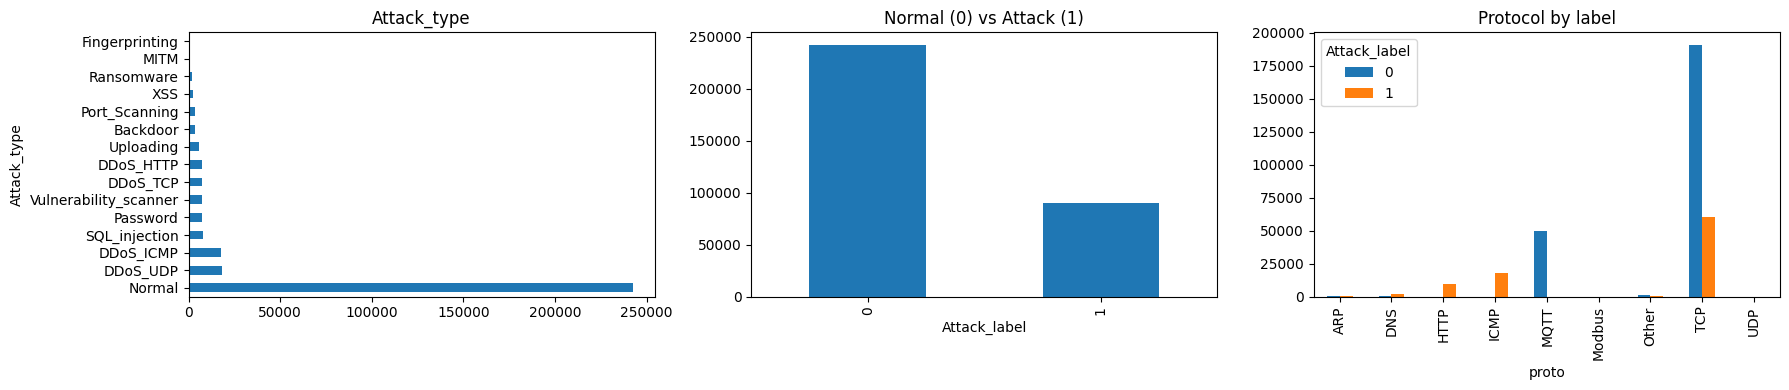

20735 unique source hosts (device proxy)
ip.src_host
192.168.0.128      144491
192.168.0.101       99803
0                   42786
192.168.0.170       24772
0.0.0.0               163
192.168.0.1           101
192.168.0.152          15
197.84.150.123          5
104.16.87.20            4
160.119.193.252         4
143.107.229.210         3
172.217.19.42           3
142.250.200.205         3
85.254.217.5            3
142.250.201.10          2
Name: count, dtype: int64


In [ ]:
import matplotlib.pyplot as plt, seaborn as sns

df['ip.src_host'] = df['ip.src_host'].astype(str).fillna('unknown')
df['ip.dst_host'] = df['ip.dst_host'].astype(str).fillna('unknown')

def active(s):
    return ~(s.isna() | s.astype(str).isin(['0', '0.0', '', 'nan']))
def A(c):
    return active(df[c]) if c in df.columns else pd.Series(False, index=df.index)

df['proto'] = np.select(
    [A('mqtt.msgtype'), A('mbtcp.len'), A('dns.qry.name'),
     A('http.request.method') | A('http.response'),
     A('icmp.checksum'), A('arp.opcode'), A('tcp.srcport'), A('udp.port')],
    ['MQTT', 'Modbus', 'DNS', 'HTTP', 'ICMP', 'ARP', 'TCP', 'UDP'], default='Other')

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
df['Attack_type'].value_counts().plot.barh(ax=ax[0], title='Attack_type')
df['Attack_label'].value_counts().plot.bar(ax=ax[1], title='Normal (0) vs Attack (1)')
pd.crosstab(df['proto'], df['Attack_label']).plot.bar(ax=ax[2], title='Protocol by label')
plt.tight_layout(); plt.show()

print(df['ip.src_host'].nunique(), 'unique source hosts (device proxy)')
print(df['ip.src_host'].value_counts().head(15))

In [ ]:
ID_COLS = ['frame.time', 'ip.src_host', 'ip.dst_host']
TARGETS = ['Attack_label', 'Attack_type']

def _hex(x):
    try:
        # Limit string length or handle huge values
        val_str = str(x).strip()
        if len(val_str) > 16:  # Too large for standard numeric conversion
            return np.nan
        return int(val_str, 16)
    except Exception:
        return np.nan

def to_num(s):
    n = pd.to_numeric(s, errors='coerce')
    if n.notna().mean() > 0.95:
        return n.fillna(0)

    # Process hex conversion safely
    h = s.map(_hex)
    if h.notna().mean() > 0.95:
        # Clip or handle excessively large values to prevent overflow
        return h.clip(lower=-(2**53), upper=2**53 - 1).fillna(0)

    if s.nunique() <= 50:
        return pd.Series(pd.factorize(s)[0], index=s.index)

    return None

num, dropped = {}, []
for c in df.columns:
    if c in ID_COLS + TARGETS + ['proto']:
        continue
    r = to_num(df[c])
    if r is None or r.nunique() <= 1:
        dropped.append(c)
    else:
        # Convert safely, fallback to float64 if values exceed float32 limits
        try:
            num[c] = r.astype('float32')
        except OverflowError:
            num[c] = r.astype('float64')

X_num = pd.DataFrame(num)
print(X_num.shape, 'numeric features kept')
print('dropped (text or constant):', dropped)

(332878, 41) numeric features kept
dropped (text or constant): ['arp.dst.proto_ipv4', 'arp.src.proto_ipv4', 'icmp.unused', 'http.file_data', 'http.request.uri.query', 'http.request.method', 'http.referer', 'http.request.full_uri', 'http.request.version', 'http.tls_port', 'tcp.options', 'tcp.payload', 'dns.qry.type', 'mqtt.msg_decoded_as', 'mqtt.msg', 'mqtt.protoname', 'mqtt.topic']


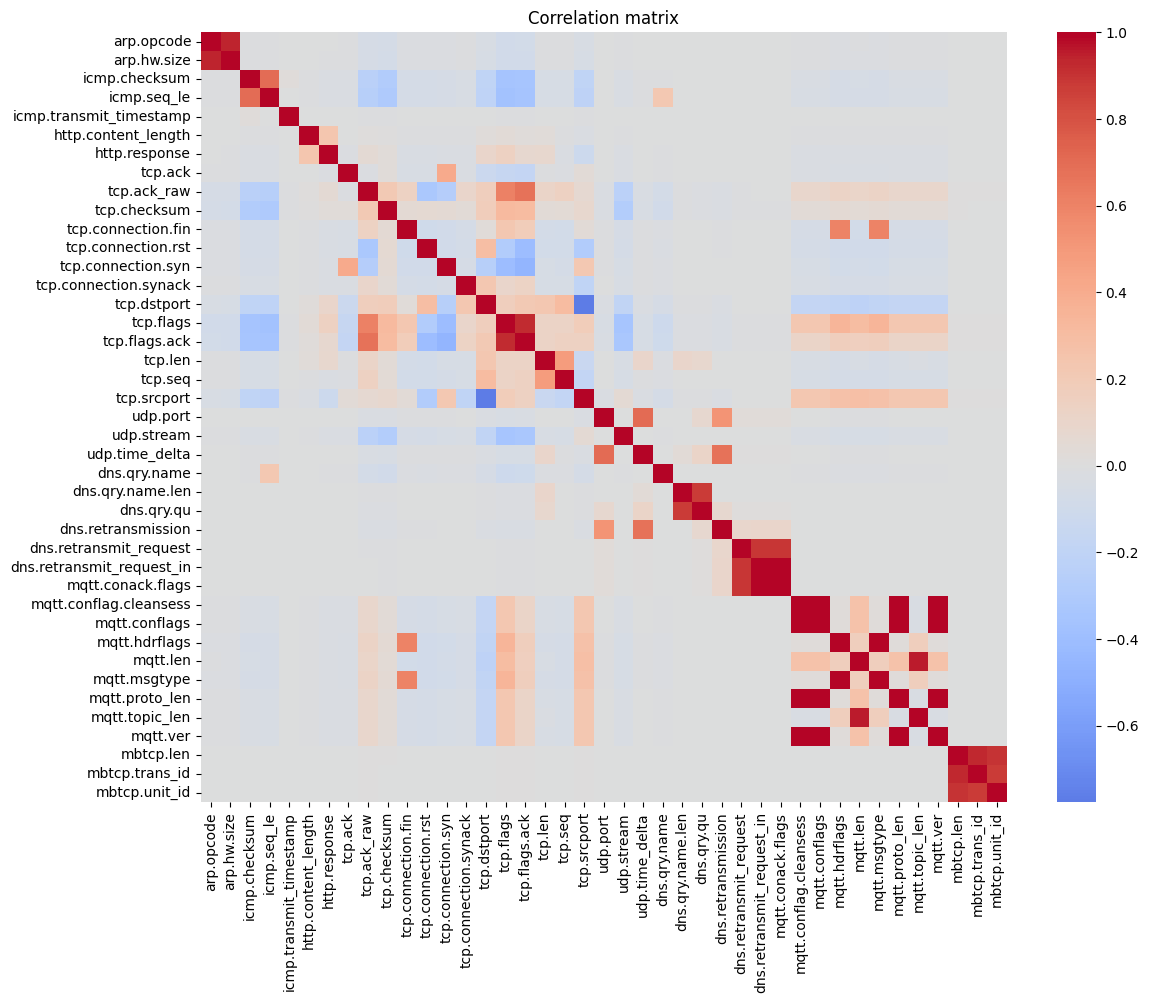

Outlier fraction, top 15:
 tcp.len                  0.219657
tcp.ack                  0.206310
tcp.seq                  0.181271
mqtt.hdrflags            0.149388
mqtt.msgtype             0.149388
mqtt.len                 0.112005
tcp.connection.rst       0.092929
tcp.connection.fin       0.086834
tcp.connection.syn       0.070566
icmp.seq_le              0.057976
udp.stream               0.055738
icmp.checksum            0.052716
tcp.connection.synack    0.045623
mqtt.proto_len           0.037383
mqtt.conflags            0.037383
dtype: float64


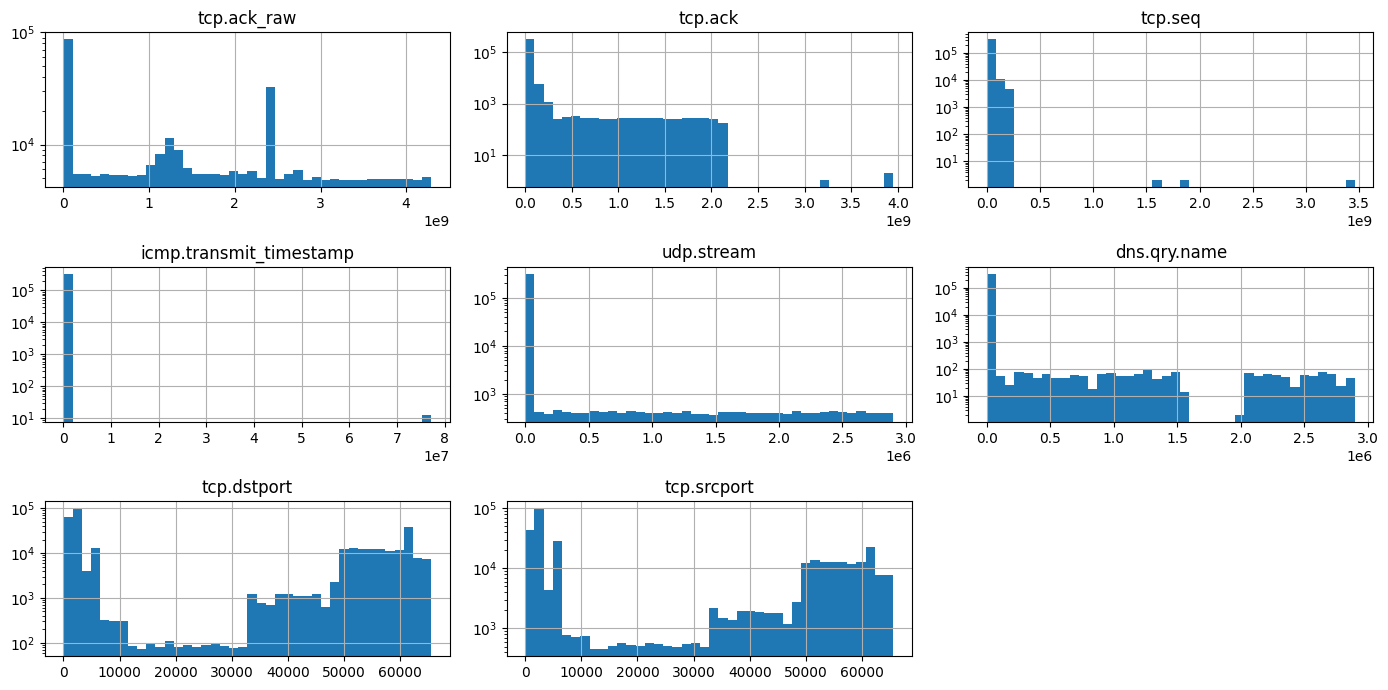

In [ ]:
plt.figure(figsize=(13, 10))
sns.heatmap(X_num.corr(), cmap='coolwarm', center=0, xticklabels=True, yticklabels=True)
plt.title('Correlation matrix'); plt.show()

q1, q3 = X_num.quantile(.25), X_num.quantile(.75); iqr = q3 - q1
out_frac = ((X_num < q1 - 1.5 * iqr) | (X_num > q3 + 1.5 * iqr)).mean().sort_values(ascending=False)
print('Outlier fraction, top 15:\n', out_frac.head(15))   # columns with IQR=0 look inflated

cols = X_num.var().sort_values(ascending=False).index[:8]
X_num[cols].hist(bins=40, figsize=(14, 7), log=True); plt.tight_layout(); plt.show()

In [ ]:
tmp = pd.DataFrame({
    'src': df['ip.src_host'], 'dst': df['ip.dst_host'], 'proto': df['proto'],
    'dport':  X_num['tcp.dstport'] if 'tcp.dstport' in X_num else 0,
    'len':    X_num['tcp.len'] if 'tcp.len' in X_num else 0,
    'syn':    X_num['tcp.connection.syn'] if 'tcp.connection.syn' in X_num else 0,
    'synack': X_num['tcp.connection.synack'] if 'tcp.connection.synack' in X_num else 0,
})
g = tmp.groupby('src')
dev = pd.DataFrame({
    'n_packets': g.size(),
    'unique_destinations': g['dst'].nunique(),
    'unique_ports': g['dport'].nunique(),
    'unique_protocols': g['proto'].nunique(),
    'mean_len': g['len'].mean(),
    'std_len': g['len'].std().fillna(0),
    'syn_count': g['syn'].sum(),
    'synack_count': g['synack'].sum(),
})
inb = tmp['dst'].value_counts().reindex(dev.index).fillna(0).values
dev['inbound_outbound_ratio'] = dev['n_packets'] / (inb + 1)
dev['request_response_ratio'] = dev['syn_count'] / (dev['synack_count'] + 1)

# temporal features disabled: frame.time has no real date and rows are out of order
if False:
    pass

dev['host_label'] = df.groupby('ip.src_host')['Attack_type'].agg(lambda s: s.value_counts().idxmax())
dev['attack_frac'] = df.groupby('ip.src_host')['Attack_label'].mean()
print(dev.shape); display(dev.head()); print(dev['host_label'].value_counts())

# attach each packet's source-host behavior to the packet-level table
beh_cols = [c for c in dev.columns if c not in ('host_label', 'attack_frac')]
beh = dev.loc[df['ip.src_host'], beh_cols].reset_index(drop=True)
beh.index = X_num.index
X_all = (pd.concat([X_num, beh.astype('float32')], axis=1)
           .replace([np.inf, -np.inf], 0).fillna(0))
print('X_all:', X_all.shape)

(20735, 12)


,n_packets,unique_destinations,unique_ports,unique_protocols,mean_len,std_len,syn_count,synack_count,inbound_outbound_ratio,request_response_ratio,host_label,attack_frac
src,,,,,,,,,,,,
0,42786,2,4,4,780.554504,1211.233765,0.0,0.0,0.724254,0.0,Normal,0.020778
0.0.0.0,163,2,1,1,0.000000,0.000000,0.0,0.0,163.000000,0.0,Normal,0.398773
0.10.35.176,1,1,1,1,0.000000,0.000000,0.0,0.0,1.000000,0.0,DDoS_ICMP,1.000000
0.100.0.49,1,1,1,1,0.000000,0.000000,0.0,0.0,1.000000,0.0,DDoS_ICMP,1.000000
0.105.75.186,1,1,1,1,0.000000,0.000000,0.0,0.0,1.000000,0.0,DDoS_ICMP,1.000000


host_label
DDoS_ICMP                14538
DDoS_TCP                  4366
DDoS_UDP                  1813
Normal                      11
XSS                          2
Vulnerability_scanner        2
DDoS_HTTP                    2
MITM                         1
Name: count, dtype: int64
X_all: (332878, 51)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import mutual_info_classif, chi2, RFE
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

y_bin, y_type = df['Attack_label'].astype(int), df['Attack_type']
Xtr, Xte, ybtr, ybte, yttr, ytte = train_test_split(
    X_all, y_bin, y_type, test_size=0.2, stratify=y_type, random_state=SEED)

# 1) correlation filter
c = Xtr.corr().abs()
upper = c.where(np.triu(np.ones(c.shape), k=1).astype(bool))
drop_corr = [col for col in upper.columns if (upper[col] > 0.95).any()]
keep1 = [col for col in Xtr.columns if col not in drop_corr and Xtr[col].std() > 0]
print(len(Xtr.columns), '->', len(keep1), 'after correlation filter')

# subsample for speed
idx = Xtr.sample(min(50000, len(Xtr)), random_state=SEED).index
Xs, ys, ysb = Xtr.loc[idx, keep1], yttr.loc[idx], ybtr.loc[idx]

K = min(30, len(keep1))
# 2) filter: mutual information, chi-square
mi  = pd.Series(mutual_info_classif(Xs, ys, random_state=SEED), index=keep1).sort_values(ascending=False)
chi = pd.Series(chi2(MinMaxScaler().fit_transform(Xs), ys)[0], index=keep1).sort_values(ascending=False)
sel_mi, sel_chi = mi.index[:K].tolist(), chi.index[:K].tolist()

# 3) wrapper: RFE on the MI shortlist
n_rfe = min(20, K)
rfe = RFE(RandomForestClassifier(n_estimators=50, max_depth=12, n_jobs=-1, random_state=SEED),
          n_features_to_select=n_rfe, step=2).fit(Xs[sel_mi], ys)
sel_rfe = [f for f, k in zip(sel_mi, rfe.support_) if k]

# 4) embedded: RF importance, L1 logistic regression, XGBoost
rf = RandomForestClassifier(n_estimators=100, max_depth=12, n_jobs=-1, random_state=SEED).fit(Xs, ys)
sel_rf = pd.Series(rf.feature_importances_, index=keep1).sort_values(ascending=False).index[:n_rfe].tolist()

l1 = LogisticRegression(penalty='l1', solver='saga', C=0.05, max_iter=300).fit(StandardScaler().fit_transform(Xs), ysb)
l1_w = pd.Series(np.abs(l1.coef_).ravel(), index=keep1)
sel_l1 = l1_w[l1_w > 0].index.tolist()

sets = {'all (after corr filter)': keep1, 'mutual_info': sel_mi, 'chi2': sel_chi,
        'RFE': sel_rfe, 'RF importance': sel_rf, 'L1': sel_l1}
try:
    from xgboost import XGBClassifier
    xgb = XGBClassifier(n_estimators=100, max_depth=6, n_jobs=-1, random_state=SEED).fit(Xs, ysb)
    sets['XGBoost importance'] = pd.Series(xgb.feature_importances_, index=keep1).sort_values(ascending=False).index[:n_rfe].tolist()
except ImportError:
    print('xgboost not installed: skipped')

# compare each subset: RF macro-F1 on Attack_type
ev_tr = Xtr.sample(min(50000, len(Xtr)), random_state=1).index
ev_te = Xte.sample(min(30000, len(Xte)), random_state=1).index
rows = []
for name, feats in sets.items():
    if not feats: continue
    m = RandomForestClassifier(n_estimators=50, n_jobs=-1, random_state=SEED).fit(Xtr.loc[ev_tr, feats], yttr.loc[ev_tr])
    rows.append((name, len(feats), f1_score(ytte.loc[ev_te], m.predict(Xte.loc[ev_te, feats]), average='macro')))
display(pd.DataFrame(rows, columns=['method', 'n_features', 'macro_F1']).sort_values('macro_F1', ascending=False))
print('RFE features:', sel_rfe)

51 -> 40 after correlation filter


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,method,n_features,macro_F1
1,mutual_info,30,0.915718
4,RF importance,20,0.915672
3,RFE,20,0.915184
6,XGBoost importance,20,0.913302
0,all (after corr filter),40,0.912037
5,L1,35,0.911580
2,chi2,30,0.886627


RFE features: ['tcp.dstport', 'tcp.srcport', 'tcp.ack', 'tcp.seq', 'tcp.flags', 'mean_len', 'inbound_outbound_ratio', 'n_packets', 'syn_count', 'unique_destinations', 'tcp.checksum', 'tcp.ack_raw', 'tcp.len', 'icmp.checksum', 'udp.stream', 'icmp.seq_le', 'http.content_length', 'tcp.connection.syn', 'http.response', 'tcp.connection.rst']


cumulative explained variance: [0.179 0.329 0.466 0.549 0.615 0.677 0.729 0.779 0.818 0.852]


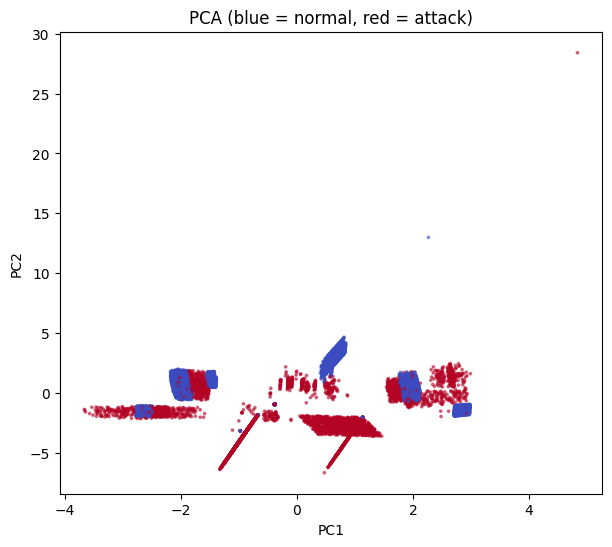

In [ ]:
FINAL = sel_rfe          # or keep1 to use every non-redundant feature
scaler = StandardScaler().fit(Xtr[FINAL])
Ztr, Zte = scaler.transform(Xtr[FINAL]), scaler.transform(Xte[FINAL])

from sklearn.decomposition import PCA
pca = PCA(n_components=min(10, Ztr.shape[1]), random_state=SEED).fit(Ztr)
print('cumulative explained variance:', pca.explained_variance_ratio_.cumsum().round(3))
Ptr, Pte = pca.transform(Ztr), pca.transform(Zte)

s = np.random.RandomState(SEED).choice(len(Ptr), min(20000, len(Ptr)), replace=False)
plt.figure(figsize=(7, 6))
plt.scatter(Ptr[s, 0], Ptr[s, 1], c=ybtr.values[s], cmap='coolwarm', s=3, alpha=.5)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.title('PCA (blue = normal, red = attack)'); plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model

n = Ztr.shape[1]
inp = layers.Input(shape=(n,))
x = layers.Dense(32, activation='relu')(inp)
x = layers.Dense(16, activation='relu')(x)
z = layers.Dense(8, name='latent')(x)
x = layers.Dense(16, activation='relu')(z)
x = layers.Dense(32, activation='relu')(x)
out = layers.Dense(n)(x)
ae, enc = Model(inp, out), Model(inp, z)
ae.compile(optimizer='adam', loss='mse')

normal = Ztr[ybtr.values == 0][:200000]
ae.fit(normal, normal, epochs=20, batch_size=512, validation_split=0.1, verbose=2)

Epoch 1/20
341/341 - 5s - 15ms/step - loss: 0.2163 - val_loss: 0.0431
Epoch 2/20
341/341 - 3s - 9ms/step - loss: 0.0212 - val_loss: 0.0112
Epoch 3/20
341/341 - 1s - 3ms/step - loss: 0.0096 - val_loss: 0.0063
Epoch 4/20
341/341 - 1s - 3ms/step - loss: 0.0058 - val_loss: 0.0070
Epoch 5/20
341/341 - 1s - 3ms/step - loss: 0.0044 - val_loss: 0.0031
Epoch 6/20
341/341 - 1s - 3ms/step - loss: 0.0033 - val_loss: 0.0025
Epoch 7/20
341/341 - 1s - 3ms/step - loss: 0.0032 - val_loss: 0.0021
Epoch 8/20
341/341 - 1s - 3ms/step - loss: 0.0028 - val_loss: 0.0036
Epoch 9/20
341/341 - 1s - 3ms/step - loss: 0.0023 - val_loss: 0.0029
Epoch 10/20
341/341 - 1s - 4ms/step - loss: 0.0019 - val_loss: 0.0013
Epoch 11/20
341/341 - 2s - 4ms/step - loss: 0.0018 - val_loss: 0.0012
Epoch 12/20
341/341 - 1s - 4ms/step - loss: 0.0019 - val_loss: 0.0010
Epoch 13/20
341/341 - 1s - 4ms/step - loss: 0.0021 - val_loss: 0.0011
Epoch 14/20
341/341 - 1s - 3ms/step - loss: 0.0013 - val_loss: 7.9906e-04
Epoch 15/20
341/341 - 1s

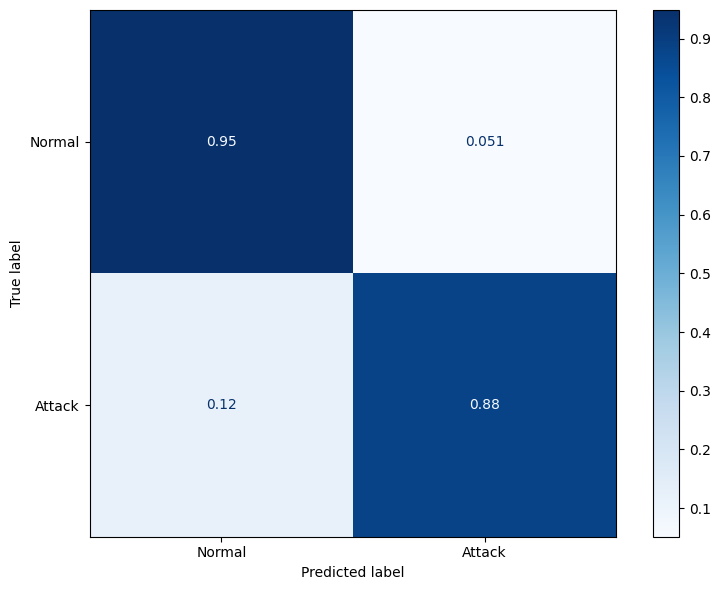

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# 1. Define reconstruction error for the test set
e_te = np.mean((Zte - ae.predict(Zte, batch_size=2048, verbose=0)) ** 2, axis=1)

# 2. Set anomaly threshold (using the 95th percentile of normal traffic as done in other cells)
thr = np.percentile(np.mean((normal - ae.predict(normal, batch_size=2048, verbose=0)) ** 2, axis=1), 95)

# 3. Predict binary labels: 1 if anomaly (reconstruction error > threshold), else 0
y_pred = (e_te > thr).astype(int)
y_true = ybte.values

# 4. Plot the confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=['Normal', 'Attack'],
    normalize='true',
    ax=ax,
    cmap='Blues'
)
plt.tight_layout()
plt.show()

Anomaly ROC-AUC (reconstruction error): 0.9709
              precision    recall  f1-score   support

      normal       0.96      0.95      0.95     48470
      attack       0.87      0.88      0.87     18106

    accuracy                           0.93     66576
   macro avg       0.91      0.91      0.91     66576
weighted avg       0.93      0.93      0.93     66576

macro-F1 with PCA components : 0.7855
macro-F1 with AE latent (8)  : 0.7605


,z0,z1,z2,z3,z4,z5,z6,z7,host_label
0,6.001290,-1.251426,8.011010,-7.259234,1.821576,7.573249,-1.763731,3.142693,Normal
0.0.0.0,-8.382698,22.362846,40.619457,-18.386169,-6.978277,45.032234,-44.861801,-9.163465,Normal
0.106.130.238,3.026103,0.219291,1.255889,-1.820666,1.158613,2.182242,-1.160601,2.796750,DDoS_ICMP
0.111.229.75,3.887944,-0.794220,3.333567,-2.083491,2.361878,0.924016,-1.810980,3.962440,DDoS_ICMP
0.13.78.117,3.820920,-0.761033,3.226029,-2.055746,2.270086,0.944096,-1.744237,3.846581,DDoS_ICMP


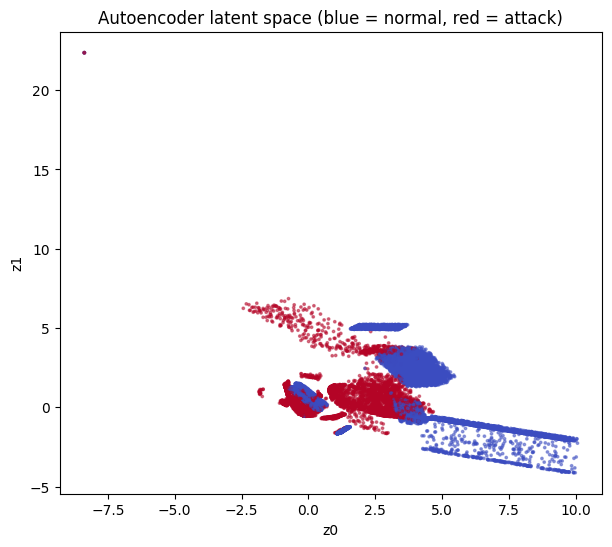

In [ ]:
from sklearn.metrics import roc_auc_score, classification_report

def recon_err(A):
    return np.mean((A - ae.predict(A, batch_size=2048, verbose=0)) ** 2, axis=1)

thr = np.percentile(recon_err(normal), 95)       # 5% false-alarm budget on normal traffic
e_te = recon_err(Zte)
print('Anomaly ROC-AUC (reconstruction error):', round(roc_auc_score(ybte, e_te), 4))
print(classification_report(ybte, (e_te > thr).astype(int), target_names=['normal', 'attack']))

Ltr, Lte = enc.predict(Ztr, batch_size=2048, verbose=0), enc.predict(Zte, batch_size=2048, verbose=0)

# PCA-10 vs latent-8 on Attack_type
sub = np.random.RandomState(SEED).choice(len(Ztr), min(150000, len(Ztr)), replace=False)
def score(Atr, Ate):
    m = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED).fit(Atr[sub], yttr.values[sub])
    return f1_score(ytte, m.predict(Ate), average='macro')
print('macro-F1 with PCA components :', round(score(Ptr, Pte), 4))
print('macro-F1 with AE latent (8)  :', round(score(Ltr, Lte), 4))

# per-device fingerprint = mean latent vector of each source host (test split)
hosts = df.loc[Xte.index, 'ip.src_host'].values
fp = pd.DataFrame(Lte, columns=[f'z{i}' for i in range(Lte.shape[1])]).groupby(hosts).mean()
fp['host_label'] = dev['host_label'].reindex(fp.index)
fp.to_csv('/content/drive/MyDrive/device_fingerprints.csv')
display(fp.head())

plt.figure(figsize=(7, 6))
ss = np.random.RandomState(SEED).choice(len(Lte), min(20000, len(Lte)), replace=False)
plt.scatter(Lte[ss, 0], Lte[ss, 1], c=ybte.values[ss], cmap='coolwarm', s=3, alpha=.5)
plt.xlabel('z0'); plt.ylabel('z1'); plt.title('Autoencoder latent space (blue = normal, red = attack)'); plt.show()

In [ ]:
import time
import numpy as np
import pandas as pd
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.metrics import roc_auc_score, f1_score
from sklearn.ensemble import RandomForestClassifier
D = normal.shape[1]      # input features
LATENT = 8

def build_ae(kind):
    inp = layers.Input(shape=(D,))
    x = inp
    if kind == 'denoising':
        x = layers.GaussianNoise(0.1)(x)       # noise only active during training
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dense(32, activation='relu')(x)
    reg = regularizers.l1(1e-5) if kind == 'sparse' else None
    z = layers.Dense(LATENT, activation='linear', activity_regularizer=reg, name='latent')(x)
    x = layers.Dense(32, activation='relu')(z)
    x = layers.Dense(64, activation='relu')(x)
    out = layers.Dense(D, activation='linear')(x)
    ae = keras.Model(inp, out)
    enc = keras.Model(inp, z)
    ae.compile(optimizer='adam', loss='mse')
    return ae, enc

results = {}
for kind in ['vanilla', 'denoising', 'sparse']:
    ae, enc = build_ae(kind)

    t0 = time.time()
    ae.fit(normal, normal, epochs=30, batch_size=2048,
           validation_split=0.1, verbose=0)
    train_time = time.time() - t0

    # anomaly detection (reconstruction error)
    err = lambda A: np.mean((A - ae.predict(A, batch_size=2048, verbose=0))**2, axis=1)
    auc = roc_auc_score(ybte, err(Zte))

    # feature extraction (latent-8 -> Random Forest)
    Ltr, Lte = enc.predict(Ztr, batch_size=2048, verbose=0), enc.predict(Zte, batch_size=2048, verbose=0)
    m = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED).fit(Ltr[sub], yttr.values[sub])
    f1 = f1_score(ytte, m.predict(Lte), average='macro')

    results[kind] = dict(train_time_s=round(train_time, 1), roc_auc=round(auc, 4), macro_f1=round(f1, 4))

pd.DataFrame(results).T

,train_time_s,roc_auc,macro_f1
vanilla,39.3,0.9890,0.7721
denoising,54.7,0.9837,0.7676
sparse,31.9,0.9794,0.7870


In [ ]:
test_hosts = df.loc[Xte.index, 'ip.src_host'].values
host_err = (pd.DataFrame({'host': test_hosts, 'err': e_te, 'attack': ybte.values})
              .groupby('host').agg(mean_err=('err', 'mean'), attack_frac=('attack', 'mean'), n=('err', 'size')))
host_err = host_err[host_err['n'] >= 5]           # ignore hosts with very few packets
host_err['flagged'] = host_err['mean_err'] > thr
print(host_err.sort_values('mean_err', ascending=False).head(15))

is_attack_host = host_err['attack_frac'] > 0.5
if is_attack_host.nunique() == 2:
    print('Device-level ROC-AUC:', round(roc_auc_score(is_attack_host, host_err['mean_err']), 4))

               mean_err  attack_frac      n  flagged
host                                                
192.168.0.170  0.806217     1.000000   4970     True
192.168.0.128  0.412335     0.305449  28869     True
192.168.0.1    0.156368     0.000000     31     True
0              0.137091     0.020169   8627     True
0.0.0.0        0.039833     0.444444     36     True
192.168.0.101  0.000554     0.000201  19916    False
Device-level ROC-AUC: 1.0


  0%|          | 0/100 [00:00<?, ?it/s]

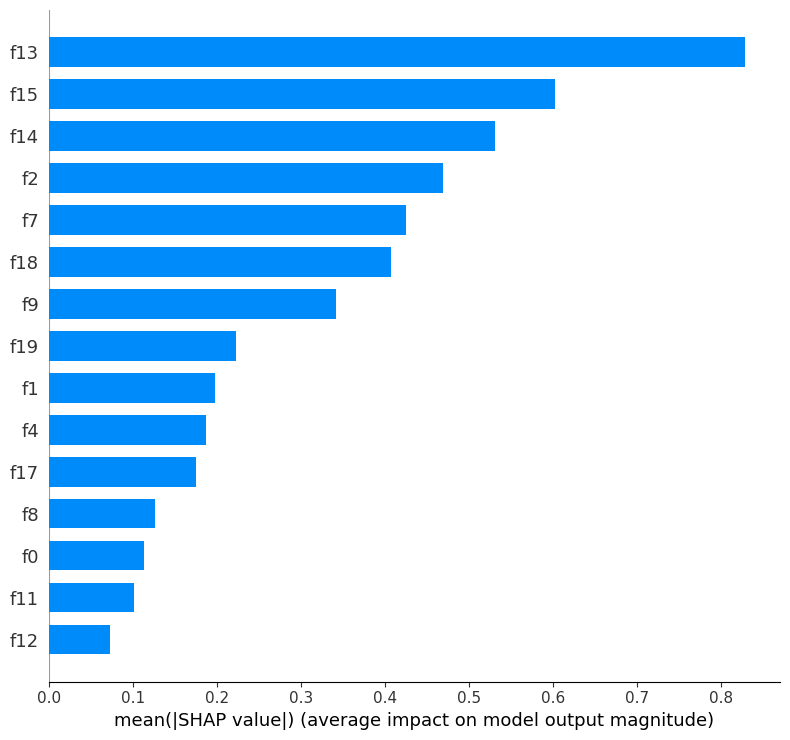

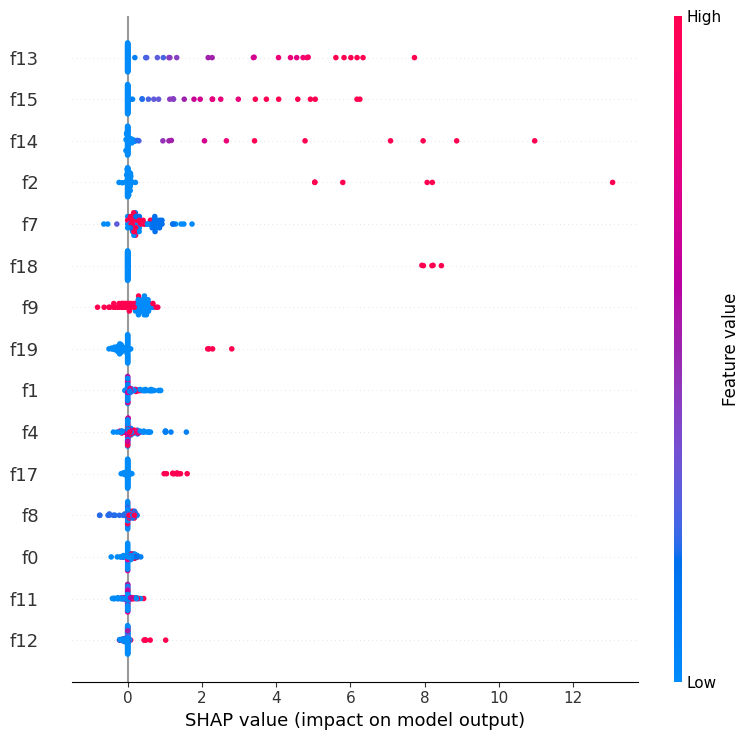

In [ ]:
!pip install -q shap

import shap, numpy as np, matplotlib.pyplot as plt

# feature names (falls back to f0, f1... if Zte is a numpy array)
feat_names = list(Zte.columns) if hasattr(Zte, 'columns') else [f'f{i}' for i in range(Zte.shape[1])]
Zte_np = np.asarray(Zte)

# model output to explain = anomaly score (reconstruction error)
def anomaly_score(A):
    A = np.asarray(A)
    return np.mean((A - ae.predict(A, batch_size=2048, verbose=0))**2, axis=1)

# background = summary of NORMAL traffic; explain a sample of ATTACK traffic
background = shap.kmeans(np.asarray(normal), 25)
attack_idx = np.where(np.asarray(ybte) == 1)[0]
rng = np.random.RandomState(SEED)
explain_idx = rng.choice(attack_idx, size=min(100, len(attack_idx)), replace=False)
X_explain = Zte_np[explain_idx]

explainer = shap.KernelExplainer(anomaly_score, background)
shap_values = explainer.shap_values(X_explain, nsamples=200)

# global importance: which features drive the anomaly score most
shap.summary_plot(shap_values, X_explain, feature_names=feat_names, plot_type='bar', max_display=15)

# direction of effect (red = high feature value pushes score up)
shap.summary_plot(shap_values, X_explain, feature_names=feat_names, max_display=15)